# RMTransformer for drone RF coverage maps

This notebook trains and tests an **RMTransformer** ([Li et al., 2025, arXiv:2501.05190](https://arxiv.org/abs/2501.05190))
on the AIRWISE dataset [`TYessine/airwise-rf-coverage-maps`](https://huggingface.co/datasets/TYessine/airwise-rf-coverage-maps).
The model predicts the ray traced **path gain map (dB)** at a drone altitude from the city height map, the ground
station position and the altitude.

**RMTransformer in short.** It is a hybrid transformer / CNN U-shaped network. A CNN stem is followed by
**4 MaxViT stages**. Each stage has an MBConv, block (local window) attention and grid (sparse global) attention,
and each one halves the resolution and doubles the channels. Then comes a **CNN decoder** of 4 `ConvTranspose2d`
upsampling blocks that concatenate the encoder features (skip connections), and a convolutional output head.

### What the paper fixes and what this notebook chooses

| | RMTransformer paper | this notebook |
|---|---|---|
| input | 256 × 256, 2 channels (buildings, BS location) | 128 × 128 (the native 1 m grid), 7 channels: height, height relative to the drone plane, validity mask, station marker, free space gain at the drone altitude, station z, altitude. The paper's maps are 2D at one height. Here the altitude and station height change, so the model must be given them |
| stem | `Conv2d`, 256 → 128 px | two 3 × 3 convs at stride 1 (128 → 128 px), so the 4 stages work at the same 64 / 32 / 16 / 8 px as in the paper |
| encoder | 4 MaxViT blocks, 128 / 256 / 512 / 1024 channels | same with `model_size="paper"`, one MaxViT block per stage. Window = grid = 8, 32 dim heads, MBConv expansion 4 (not given in the paper, MaxViT defaults) |
| decoder | 4 CNN blocks with `ConvTranspose2d`, concatenated skips (Eq. 6) | `ConvTranspose2d` ×2, concat, 2 × (Conv 3 × 3, BN, GELU). The 4th block uses the stem features as skip |
| target | received power, [-254, 0] dBm → [0, 1] | path gain, [-150, -50] dB → [0, 1] (-150 dB = no signal) |
| loss | not given | MSE over valid cells only (cells inside buildings taller than the drone plane are left out) |
| optimiser | Adam, lr 1e-4 → 1e-5, 50 epochs, batch 8 | same (AdamW with weight decay 0, which is Adam), 500 step warm-up and cosine decay, bf16 mixed precision, random rotation / mirror augmentation |
| metrics | RMSE, coverage prediction error at a threshold | RMSE in dB over valid cells, MAE, bias, RMSE where there is signal, coverage error and RMSE near the coverage boundary at several thresholds, per family and per altitude, speed against ray tracing |

### Running it
* A CUDA GPU is strongly recommended. Training on the CPU will work but is far too slow for 50 epochs.
* The dataset repo is **private**. Log in once with `hf auth login` (or set the `HF_TOKEN` environment
  variable) using an account that has access. The four split files are about 1 GB and are cached by `huggingface_hub`.
* Everything (checkpoints, history, results) goes to `runs/rmtransformer/` next to the notebook. Training resumes from
  `last.pt` if the kernel dies. Delete the folder to start over.
* For a quick try, set `model_size="small"` and fewer `epochs` in the configuration cell.

In [3]:
# Installs everything from the repo's requirements.txt, including the CUDA build of PyTorch
# (plain `pip install torch` gives a CPU-only build on Windows). Restart the kernel after it runs.
# %pip install -r ../requirements.txt

In [4]:
import json
import math
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from tqdm.auto import tqdm
except ImportError:              # progress bars are optional
    tqdm = None

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
# bf16 needs no loss scaling. Older GPUs without bf16 fall back to fp16 with a GradScaler.
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16

print("torch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)}, AMP {AMP_DTYPE})" if DEVICE.type == "cuda" else "(no GPU found)")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

torch 2.15.0+cu132 | device: cuda (NVIDIA GeForce RTX 4070 Laptop GPU, AMP torch.bfloat16)


## Configuration
All settings live in `CFG`, which is saved with every checkpoint.

In [5]:
CFG = dict(
    # --- data
    repo_id="TYessine/airwise-rf-coverage-maps",
    revision=None,                # pin a commit hash or tag of the dataset repo for reproducibility
    data_dir=None,                # folder that already holds <split>.npz (None = download from the Hub)
    splits=("train", "val", "test", "ood"),
    run_dir="runs/rmtransformer",
    seed=0,
    # --- physics and normalisation
    freq_hz=2.4e9,
    floor_db=-150.0,              # dataset floor: -150 dB means no ray arrived
    max_db=-50.0,                 # top of the [0, 1] scale (highest gain in the data is about -54 dB)
    height_scale=60.0,            # m, heights, altitudes and station z are divided by this
    tx_sigma=1.0,                 # cells, width of the Gaussian station marker
    in_channels=("height", "rel_height", "valid", "tx", "fspl", "tx_z", "altitude"),
    # --- model
    model_size="paper",           # "paper": 128-1024 channels as in the paper, "small": 64-512
    window=8,                     # MaxViT block size P and grid size G
    head_dim=32,
    mbconv_expand=4,
    drop_path=0.1,
    # --- training (paper: Adam, lr 1e-4 -> 1e-5, 50 epochs, batch 8)
    epochs=50,
    batch_size=8,
    lr=1e-4,
    min_lr=1e-5,
    warmup_steps=500,
    weight_decay=0.0,             # 0 = plain Adam as in the paper
    grad_clip=1.0,
    augment=True,                 # random 90 degree rotations and mirroring (see the input section)
    amp=True,
    loss="mse",                   # "mse" (the paper reports RMSE) or "huber"
    huber_delta=0.05,             # in [0, 1] units, 0.05 = 5 dB
    eval_batch_size=32,
    max_val_maps=None,            # validate on an evenly spaced subset each epoch to save time (None = all)
    # --- evaluation
    coverage_thresholds_db=(-80.0, -100.0, -110.0),   # path gain needed for a link, e.g. -110 dB = 20 dBm Tx, -90 dBm Rx
    boundary_width=2,             # cells on each side of the coverage boundary counted as "boundary"
)

MODEL_PRESETS = dict(
    paper=dict(stem_dim=128, dims=(128, 256, 512, 1024), depths=(1, 1, 1, 1)),
    small=dict(stem_dim=64, dims=(64, 128, 256, 512), depths=(1, 1, 1, 1)),
)

RUN_DIR = Path(CFG["run_dir"])
RUN_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(CFG["seed"])

## 1. Data
Each split file holds (see the dataset card):

| array | shape | meaning |
|---|---|---|
| `heights` | (S, 128, 128) | surface height of every scene (terrain + buildings), m |
| `scene_names`, `scene_source` | (S,) | scene name (`<family>_<NNNN>`) and who traced it |
| `scene_idx` | (N,) | scene of every map |
| `station_pos` | (N, 3) | ground station x, y, z, m |
| `altitude` | (N,) | drone altitude (map plane), 15 / 30 / 45 / 60 m |
| `target_db` | (N, 128, 128) | path gain, dB, floored at -150 |
| `rt_time` | (N,) | ray tracing time of the map, s |

A cell is **valid** when the drone can be there: `heights[scene_idx] < altitude - 0.5`. Only valid cells are used in
the loss and the metrics. The splits are `train` / `val` / `test` (families blocks, grid, downtown) and `ood`
(canyon, courtyard, hilly, never seen in training). `val` is used for model selection, `test` and `ood` are reported
separately.

In [6]:
from huggingface_hub import hf_hub_download

# The repo is private: log in once with `hf auth login`, set HF_TOKEN, or uncomment the next two lines.
# from huggingface_hub import login
# login()

paths = {}
for split in CFG["splits"]:
    if CFG["data_dir"] is not None:
        paths[split] = Path(CFG["data_dir"]) / f"{split}.npz"
    else:
        paths[split] = Path(hf_hub_download(CFG["repo_id"], f"{split}.npz", repo_type="dataset",
                                            revision=CFG["revision"]))
    print(f"{split:5s} {paths[split]}  ({paths[split].stat().st_size / 1e6:.0f} MB)")

try:   # the exact ray tracing settings, kept with the run for reference
    rt_settings = json.loads(Path(hf_hub_download(CFG["repo_id"], "settings.json", repo_type="dataset",
                                                  revision=CFG["revision"])).read_text())
    (RUN_DIR / "rt_settings.json").write_text(json.dumps(rt_settings, indent=2))
    print("ray tracing settings:", {k: rt_settings[k] for k in ("frequency", "samples", "max_depth") if k in rt_settings})
except Exception as e:
    print("settings.json not read:", e)

train C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\train.npz  (660 MB)
val   C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\val.npz  (83 MB)
test  C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\test.npz  (82 MB)
ood   C:\Users\ASUS\.cache\huggingface\hub\datasets--TYessine--airwise-rf-coverage-maps\snapshots\c00b7ff8873213ed9e083125b2c101de5a6f4808\ood.npz  (165 MB)
ray tracing settings: {'frequency': 2400000000.0, 'samples': 100000000, 'max_depth': 8}


In [7]:
class CoverageSplit:
    """One split held in CPU memory as torch tensors. Height maps are stored once per scene and paired with the
    maps through scene_idx, so the train split takes about 0.9 GB."""

    def __init__(self, path, name):
        self.name = name
        with np.load(path) as d:
            self.heights = torch.from_numpy(np.ascontiguousarray(d["heights"], dtype=np.float32))
            self.scene_idx = torch.from_numpy(np.ascontiguousarray(d["scene_idx"], dtype=np.int64))
            self.station = torch.from_numpy(np.ascontiguousarray(d["station_pos"], dtype=np.float32))
            self.altitude = torch.from_numpy(np.ascontiguousarray(d["altitude"], dtype=np.float32))
            self.target = torch.from_numpy(np.ascontiguousarray(d["target_db"], dtype=np.float32))
            self.rt_time = np.asarray(d["rt_time"], dtype=np.float32)
            self.scene_names = d["scene_names"].astype(str)
            self.scene_source = (d["scene_source"].astype(str) if "scene_source" in d.files
                                 else np.full(len(self.scene_names), "unknown"))
        si = self.scene_idx.numpy()
        self.family = np.array([n.rsplit("_", 1)[0] for n in self.scene_names])[si]   # per map
        self.source = self.scene_source[si]                                         # per map

    def __len__(self):
        return len(self.target)

    def batch(self, idx, device):
        """heights (B,H,W), station (B,3), altitude (B,), target_db (B,H,W) of the maps idx, on device."""
        idx = torch.as_tensor(np.asarray(idx), dtype=torch.long)
        return (self.heights[self.scene_idx[idx]].to(device, non_blocking=True),
                self.station[idx].to(device, non_blocking=True),
                self.altitude[idx].to(device, non_blocking=True),
                self.target[idx].to(device, non_blocking=True))

    def __repr__(self):
        fams, counts = np.unique(self.family, return_counts=True)
        return (f"{self.name}: {len(self.scene_names)} scenes, {len(self)} maps, "
                f"maps per family {dict(zip(fams.tolist(), counts.tolist()))}")

In [8]:
data = {s: CoverageSplit(paths[s], s) for s in CFG["splits"]}
train_set, val_set, test_set, ood_set = (data[s] for s in ("train", "val", "test", "ood"))
for d in data.values():
    print(d)

# quick statistics over valid cells (on a sample of maps, to keep it fast)
for d in data.values():
    k = np.linspace(0, len(d) - 1, min(len(d), 500)).astype(int)
    h, _, alt, tgt = d.batch(k, "cpu")
    valid = h < alt[:, None, None] - 0.5
    t = tgt[valid]
    sig = t[t > CFG["floor_db"]]
    print(f"{d.name:5s} altitudes {np.unique(d.altitude.numpy()).tolist()} | valid {valid.float().mean():.1%} | "
          f"no signal {(t <= CFG['floor_db']).float().mean():.1%} | signal 5/50/100 pct "
          f"{np.percentile(sig.numpy(), [5, 50, 100]).round(1).tolist()} dB | median rt_time {np.median(d.rt_time):.2f} s")

train: 1080 scenes, 12960 maps, maps per family {'blocks': 4320, 'downtown': 4320, 'grid': 4320}
val: 135 scenes, 1620 maps, maps per family {'blocks': 540, 'downtown': 540, 'grid': 540}
test: 135 scenes, 1620 maps, maps per family {'blocks': 540, 'downtown': 540, 'grid': 540}
ood: 270 scenes, 3240 maps, maps per family {'canyon': 1080, 'courtyard': 1080, 'hilly': 1080}
train altitudes [15.0, 30.0, 45.0, 60.0] | valid 95.5% | no signal 1.7% | signal 5/50/100 pct [-118.5, -81.5, -54.1] dB | median rt_time 0.31 s
val   altitudes [15.0, 30.0, 45.0, 60.0] | valid 95.1% | no signal 1.7% | signal 5/50/100 pct [-116.9, -81.3, -54.1] dB | median rt_time 0.31 s
test  altitudes [15.0, 30.0, 45.0, 60.0] | valid 94.9% | no signal 1.9% | signal 5/50/100 pct [-118.6, -82.2, -54.0] dB | median rt_time 0.31 s
ood   altitudes [15.0, 30.0, 45.0, 60.0] | valid 94.2% | no signal 3.7% | signal 5/50/100 pct [-120.6, -80.8, -54.2] dB | median rt_time 0.29 s


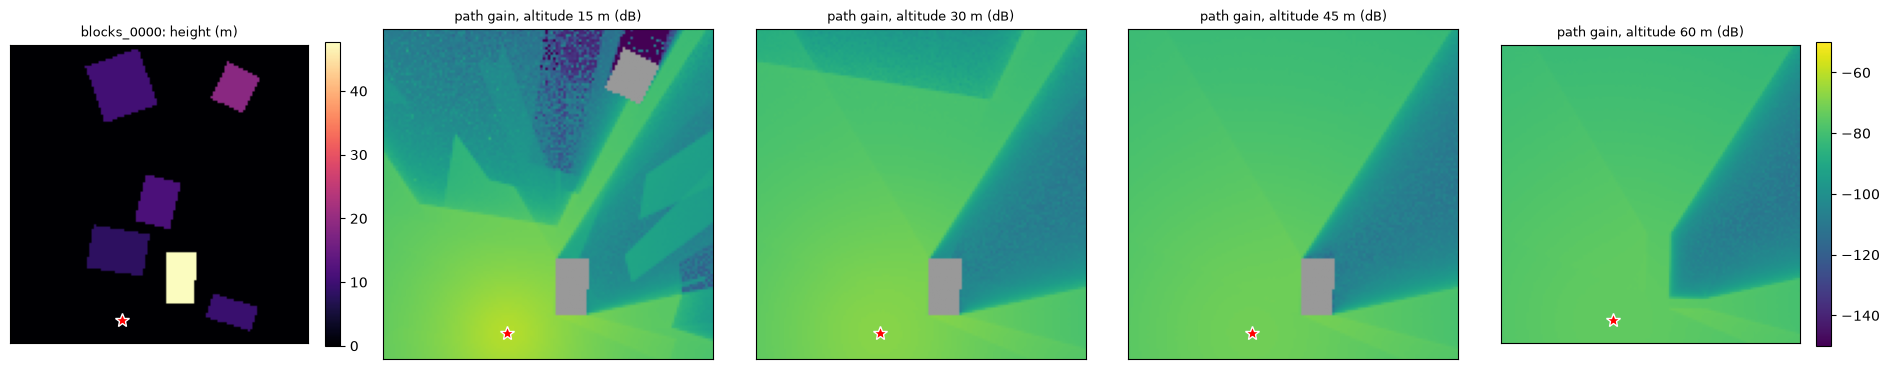

In [9]:
def show_map(ax, img, valid=None, title="", vmin=None, vmax=None, cmap="viridis", station=None):
    img = np.asarray(img, dtype=float).copy()
    if valid is not None:
        img = np.ma.masked_where(~np.asarray(valid), img)
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("0.6")                       # cells inside buildings (not valid) in grey
    # cell [i, j] has its centre at x = j - 63.5, y = i - 63.5: rows run along y, so origin="lower" puts +y up
    n = img.shape[0]
    im = ax.imshow(img, origin="lower", cmap=cm, vmin=vmin, vmax=vmax,
                   extent=(-n / 2, n / 2, -n / 2, n / 2))
    if station is not None:
        station = np.asarray(station, dtype=float)
        ax.plot(station[0], station[1], "r*", ms=10, mec="w")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]), ax.set_yticks([])
    return im


# one scene: the 4 altitudes of its first station (the maps of a scene are stored station by station, altitudes increasing)
k0 = 0
ks = [k0 + a for a in range(4)]
h, st, alt, tgt = train_set.batch(ks, "cpu")
fig, axes = plt.subplots(1, 5, figsize=(19, 4))
im = show_map(axes[0], h[0], title=f"{train_set.scene_names[int(train_set.scene_idx[k0])]}: height (m)",
              cmap="magma", station=st[0])
plt.colorbar(im, ax=axes[0], fraction=0.046)
for a in range(4):
    im = show_map(axes[a + 1], tgt[a], h[a] < alt[a] - 0.5, f"path gain, altitude {alt[a]:.0f} m (dB)",
                  CFG["floor_db"], CFG["max_db"], station=st[a])
plt.colorbar(im, ax=axes[-1], fraction=0.046)
plt.tight_layout()
plt.show()

## 2. Model inputs, target and augmentation
The input channels are built on the GPU for each batch from `heights`, `station_pos` and `altitude`:

| channel | meaning |
|---|---|
| `height` | surface height / 60 m |
| `rel_height` | (altitude − height) / 60 m: how far the drone plane is above the surface |
| `valid` | 1 where the drone can be (`height < altitude − 0.5`) |
| `tx` | Gaussian marker (σ = 1 cell) at the station's x, y. This is the paper's "BS location" channel |
| `fspl` | free space path gain from the station to every cell of the drone plane, 20 log10(λ / 4πd), on the target scale. It is a physics prior that also carries the station height and the altitude |
| `tx_z`, `altitude` | constant planes with station z / 60 m and altitude / 60 m |

Drop names from `CFG["in_channels"]` to train on fewer channels, e.g. `("height", "tx", "altitude")` to stay closer to
the paper.

**Target.** `y = (clip(target_db, -150) + 150) / 100`, so -150 dB → 0 and -50 dB → 1, as the paper scales its maps
to [0, 1].

**Augmentation.** The antennas are isotropic and vertically polarised and the materials are isotropic, so the
propagation does not change under a rotation about the vertical axis or a mirror in a vertical plane. Each training
sample gets one of the 8 rotations / mirrors of the square, applied to the inputs, the target and the mask together.
The station marker and the distance map move with them.

In [10]:
WAVELENGTH = 299_792_458.0 / CFG["freq_hz"]


def db_to_unit(db, cfg=CFG):
    return (db - cfg["floor_db"]) / (cfg["max_db"] - cfg["floor_db"])


def unit_to_db(u, cfg=CFG):
    return u * (cfg["max_db"] - cfg["floor_db"]) + cfg["floor_db"]


def free_space_gain_db(d):
    return 20.0 * torch.log10(WAVELENGTH / (4.0 * math.pi * d))


def plane_geometry(heights, station, altitude):
    """dx, dy (B,H,W) from the station to every cell centre, and the 3D distance to the drone plane."""
    B, H, W = heights.shape
    dev = heights.device
    xs = torch.arange(W, device=dev, dtype=torch.float32) - (W - 1) / 2     # x of column j = j - 63.5
    ys = torch.arange(H, device=dev, dtype=torch.float32) - (H - 1) / 2     # y of row i    = i - 63.5
    dx = xs.view(1, 1, W) - station[:, 0].view(B, 1, 1)
    dy = ys.view(1, H, 1) - station[:, 1].view(B, 1, 1)
    dz = (altitude - station[:, 2]).view(B, 1, 1)
    d3 = torch.sqrt(dx ** 2 + dy ** 2 + dz ** 2).clamp_min(1.0)
    return dx.expand(B, H, W), dy.expand(B, H, W), d3


def make_inputs(heights, station, altitude, cfg=CFG):
    """Model input (B, C, H, W) and validity mask (B, H, W) for one batch."""
    B, H, W = heights.shape
    dx, dy, d3 = plane_geometry(heights, station, altitude)
    alt = altitude.view(B, 1, 1)
    valid = heights < alt - 0.5
    hs = cfg["height_scale"]
    channels = dict(
        height=lambda: heights / hs,
        rel_height=lambda: (alt - heights) / hs,
        valid=lambda: valid.float(),
        tx=lambda: torch.exp(-(dx ** 2 + dy ** 2) / (2 * cfg["tx_sigma"] ** 2)),
        fspl=lambda: db_to_unit(free_space_gain_db(d3), cfg),
        tx_z=lambda: (station[:, 2] / hs).view(B, 1, 1).expand(B, H, W),
        altitude=lambda: (alt / hs).expand(B, H, W),
    )
    x = torch.stack([channels[c]() for c in cfg["in_channels"]], dim=1)
    return x, valid


def augment_d4(*tensors):
    """Apply the same random rotation (k * 90 deg) and optional mirror to every sample of each (B, ..., H, W) tensor."""
    B = tensors[0].shape[0]
    ks = torch.randint(0, 4, (B,)).tolist()
    flips = torch.randint(0, 2, (B,)).tolist()
    out = [t.clone() for t in tensors]
    for b in range(B):
        for o, t in zip(out, tensors):
            v = t[b].flip(-1) if flips[b] else t[b]
            o[b] = torch.rot90(v, ks[b], dims=(-2, -1))
    return out


def prepare_batch(heights, station, altitude, target_db, augment=False, cfg=CFG):
    x, valid = make_inputs(heights, station, altitude, cfg)
    y = db_to_unit(target_db.clamp_min(cfg["floor_db"]), cfg)
    if augment:
        x, y, valid = augment_d4(x, y, valid)
    return x, y, valid

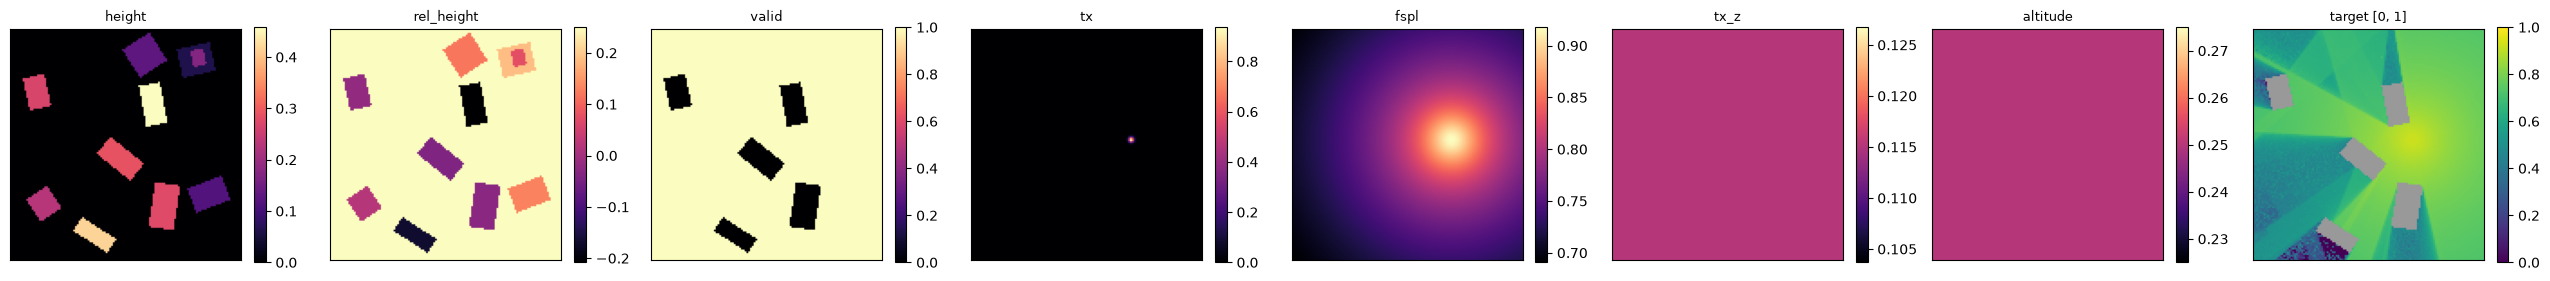

In [11]:
# the input channels of one map
h, st, alt, tgt = val_set.batch([0], DEVICE)
x, valid = make_inputs(h, st, alt)
fig, axes = plt.subplots(1, len(CFG["in_channels"]) + 1, figsize=(3.2 * (len(CFG["in_channels"]) + 1), 3.4))
for ax, name, img in zip(axes, CFG["in_channels"], x[0].cpu()):
    im = show_map(ax, img, title=name, cmap="magma")
    plt.colorbar(im, ax=ax, fraction=0.046)
im = show_map(axes[-1], db_to_unit(tgt[0].clamp_min(CFG["floor_db"])).cpu(), valid[0].cpu(), "target [0, 1]", 0, 1)
plt.colorbar(im, ax=axes[-1], fraction=0.046)
plt.tight_layout()
plt.show()

## 3. RMTransformer

```
input (C×128×128)
  └─ stem: 2 × Conv3×3-BN-GELU ───────────────────────────────── s0 (128×128×128) ──────────────┐
      └─ MaxViT 1 (MBConv stride 2, block attn, grid attn) ─ s1 (128×64×64) ──────────────┐     │
          └─ MaxViT 2 ────────────────────────────────────── s2 (256×32×32) ────────┐     │     │
              └─ MaxViT 3 ───────────────────────────────── s3 (512×16×16) ──┐      │     │     │
                  └─ MaxViT 4 ──────────────────────────── s4 (1024×8×8)     │      │     │     │
                      └─ up ×2, concat s3, 2 conv ── 512×16×16 ◄─────────────┘      │     │     │
                          └─ up ×2, concat s2 ────── 256×32×32 ◄────────────────────┘     │     │
                              └─ up ×2, concat s1 ── 128×64×64 ◄──────────────────────────┘     │
                                  └─ up ×2, concat s0 ── 128×128×128 ◄──────────────────────────┘
                                      └─ head: Conv3×3-BN-GELU, Conv1×1 → 1×128×128 (path gain in [0, 1])
```

A **MaxViT block** (Tu et al., ECCV 2022) is an MBConv (pre-norm, 1 × 1 expand, 3 × 3 depthwise, squeeze and excite,
1 × 1 project, residual). It is followed by two pre-norm transformer layers with relative position bias. The first
attends inside non-overlapping P × P windows (local, *block attention*). The second attends across a G × G grid of
cells spaced H / G apart (sparse global, *grid attention*). Together they give a global receptive field at every
stage at linear cost, which matters here: a building far from the station can shadow a whole region of the map.

In [12]:
def drop_path(x, p, training):
    """Stochastic depth: drop the residual branch of whole samples."""
    if p == 0.0 or not training:
        return x
    keep = 1.0 - p
    mask = x.new_empty((x.shape[0],) + (1,) * (x.ndim - 1)).bernoulli_(keep)
    return x * mask / keep


class DropPath(nn.Module):
    def __init__(self, p=0.0):
        super().__init__()
        self.p = p

    def forward(self, x):
        return drop_path(x, self.p, self.training)


def conv_bn_act(cin, cout, k=3, stride=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout), nn.GELU())


class SqueezeExcite(nn.Module):
    def __init__(self, ch, reduced):
        super().__init__()
        self.fc1 = nn.Conv2d(ch, reduced, 1)
        self.fc2 = nn.Conv2d(reduced, ch, 1)

    def forward(self, x):
        s = x.mean((2, 3), keepdim=True)
        return x * torch.sigmoid(self.fc2(F.silu(self.fc1(s))))


class MBConv(nn.Module):
    """MaxViT's inverted residual: pre-norm, 1x1 expand, 3x3 depthwise (stride s), SE, 1x1 project, residual."""

    def __init__(self, cin, cout, stride=1, expand=4, se_ratio=0.25, drop_path=0.0):
        super().__init__()
        hid = cout * expand
        self.norm = nn.BatchNorm2d(cin)
        self.expand = nn.Sequential(nn.Conv2d(cin, hid, 1, bias=False), nn.BatchNorm2d(hid), nn.GELU())
        self.dw = nn.Sequential(nn.Conv2d(hid, hid, 3, stride, 1, groups=hid, bias=False), nn.BatchNorm2d(hid),
                                nn.GELU())
        self.se = SqueezeExcite(hid, max(8, int(cout * se_ratio)))
        self.project = nn.Conv2d(hid, cout, 1)
        if stride == 1 and cin == cout:
            self.shortcut = nn.Identity()
        else:
            self.shortcut = nn.Sequential(nn.AvgPool2d(stride) if stride > 1 else nn.Identity(), nn.Conv2d(cin, cout, 1))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):
        return self.shortcut(x) + self.drop_path(self.project(self.se(self.dw(self.expand(self.norm(x))))))


class RelPosAttention(nn.Module):
    """Multi-head self-attention over the size x size tokens of one partition, with a learned relative position bias."""

    def __init__(self, dim, size, head_dim=32):
        super().__init__()
        assert dim % head_dim == 0, f"dim {dim} is not a multiple of head_dim {head_dim}"
        self.heads, self.head_dim = dim // head_dim, head_dim
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.rel_bias = nn.Parameter(torch.zeros(self.heads, (2 * size - 1) ** 2))
        nn.init.trunc_normal_(self.rel_bias, std=0.02)
        c = torch.stack(torch.meshgrid(torch.arange(size), torch.arange(size), indexing="ij")).flatten(1)  # 2, N
        rel = c[:, :, None] - c[:, None, :] + size - 1                                                    # 2, N, N
        self.register_buffer("rel_index", rel[0] * (2 * size - 1) + rel[1], persistent=False)

    def forward(self, x):                                     # (B', N, C)
        Bp, N, C = x.shape
        q, k, v = self.qkv(x).view(Bp, N, 3, self.heads, self.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
        bias = self.rel_bias[:, self.rel_index].unsqueeze(0).to(q.dtype)    # 1, heads, N, N
        x = F.scaled_dot_product_attention(q, k, v, attn_mask=bias)
        return self.proj(x.transpose(1, 2).reshape(Bp, N, C))


def window_partition(x, p):          # (B,H,W,C) -> (B*H/p*W/p, p*p, C): local p x p windows
    B, H, W, C = x.shape
    return x.view(B, H // p, p, W // p, p, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, p * p, C)


def window_reverse(t, p, B, H, W):
    return t.view(B, H // p, W // p, p, p, -1).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, -1)


def grid_partition(x, g):            # (B,H,W,C) -> (B*H/g*W/g, g*g, C): g x g cells spaced H/g apart
    B, H, W, C = x.shape
    return x.view(B, g, H // g, g, W // g, C).permute(0, 2, 4, 1, 3, 5).reshape(-1, g * g, C)


def grid_reverse(t, g, B, H, W):
    return t.view(B, H // g, W // g, g, g, -1).permute(0, 3, 1, 4, 2, 5).reshape(B, H, W, -1)


class PartitionAttention(nn.Module):
    """Pre-norm transformer layer (attention + MLP) on local windows ("block") or on a sparse global grid ("grid")."""

    def __init__(self, dim, mode, size, head_dim=32, mlp_ratio=4, drop_path=0.0):
        super().__init__()
        assert mode in ("block", "grid")
        self.mode, self.size = mode, size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = RelPosAttention(dim, size, head_dim)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Linear(dim * mlp_ratio, dim))
        self.drop_path = DropPath(drop_path)

    def forward(self, x):                                     # (B, H, W, C)
        B, H, W, _ = x.shape
        s = self.size
        assert H % s == 0 and W % s == 0, f"feature map {H}x{W} is not divisible by the window / grid size {s}"
        part, rev = (window_partition, window_reverse) if self.mode == "block" else (grid_partition, grid_reverse)
        x = x + self.drop_path(rev(self.attn(part(self.norm1(x), s)), s, B, H, W))
        return x + self.drop_path(self.mlp(self.norm2(x)))


class MaxViTBlock(nn.Module):
    """MBConv -> block attention -> grid attention."""

    def __init__(self, cin, cout, stride, window, head_dim, expand, drop_path):
        super().__init__()
        self.mbconv = MBConv(cin, cout, stride, expand, drop_path=drop_path)
        self.block_attn = PartitionAttention(cout, "block", window, head_dim, drop_path=drop_path)
        self.grid_attn = PartitionAttention(cout, "grid", window, head_dim, drop_path=drop_path)

    def forward(self, x):
        x = self.mbconv(x).permute(0, 2, 3, 1)                # channels last for the attention layers
        x = self.grid_attn(self.block_attn(x))
        return x.permute(0, 3, 1, 2).contiguous()


class DecoderBlock(nn.Module):
    """ConvTranspose2d x2 upsampling, concatenation with the encoder skip (Eq. 6 of the paper), two 3x3 convs."""

    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2)
        self.fuse = nn.Sequential(conv_bn_act(cout + cskip, cout), conv_bn_act(cout, cout))

    def forward(self, x, skip):
        return self.fuse(torch.cat([self.up(x), skip], dim=1))


class RMTransformer(nn.Module):
    """CNN stem -> 4 MaxViT stages (each /2) -> 4 ConvTranspose2d decoder blocks with skips -> conv head."""

    def __init__(self, in_ch, stem_dim=128, dims=(128, 256, 512, 1024), depths=(1, 1, 1, 1), window=8, head_dim=32,
                 mbconv_expand=4, drop_path=0.1):
        super().__init__()
        self.stem = nn.Sequential(conv_bn_act(in_ch, stem_dim), conv_bn_act(stem_dim, stem_dim))
        rates = torch.linspace(0, drop_path, sum(depths)).tolist()
        self.stages, cin, r = nn.ModuleList(), stem_dim, 0
        for dim, depth in zip(dims, depths):
            blocks = []
            for i in range(depth):
                blocks.append(MaxViTBlock(cin if i == 0 else dim, dim, 2 if i == 0 else 1, window, head_dim,
                                          mbconv_expand, rates[r]))
                r += 1
            self.stages.append(nn.Sequential(*blocks))
            cin = dim
        skips = [stem_dim, *dims[:-1]]                        # channels of s0, s1, s2, s3
        self.decoder, c = nn.ModuleList(), dims[-1]
        for cs in reversed(skips):
            self.decoder.append(DecoderBlock(c, cs, cs))
            c = cs
        self.head = nn.Sequential(conv_bn_act(c, c // 2), nn.Conv2d(c // 2, 1, 1))
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

    def forward(self, x):
        feats = [self.stem(x)]
        for stage in self.stages:
            feats.append(stage(feats[-1]))
        y = feats[-1]
        for block, skip in zip(self.decoder, reversed(feats[:-1])):
            y = block(y, skip)
        return self.head(y).squeeze(1)                        # (B, H, W), path gain on the [0, 1] scale

In [13]:
MODEL_KWARGS = dict(in_ch=len(CFG["in_channels"]), **MODEL_PRESETS[CFG["model_size"]], window=CFG["window"],
                    head_dim=CFG["head_dim"], mbconv_expand=CFG["mbconv_expand"], drop_path=CFG["drop_path"])
model = RMTransformer(**MODEL_KWARGS).to(DEVICE)
print(f"RMTransformer ({CFG['model_size']}): {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

model.eval()
with torch.no_grad():
    print("output shape:", tuple(model(torch.zeros(2, MODEL_KWARGS["in_ch"], 128, 128, device=DEVICE)).shape))

RMTransformer (paper): 58.3 M parameters
output shape: (2, 128, 128)


## 4. Loss and metrics
**Loss:** MSE between prediction and target on the [0, 1] scale, averaged over the **valid cells** only.

**Metrics.** These are computed in dB over valid cells, after clipping the prediction to [-150, -50] dB:
* `rmse_db`: the mean over maps of each map's RMSE, as the dataset card suggests. `rmse_db_pooled` is the RMSE
  over all valid cells of the split.
* `nrmse`: the pooled RMSE on the [0, 1] scale. This is the paper's RMSE, but it is **not directly comparable**
  with the paper's numbers, whose scale spans 254 dB, not 100 dB.
* `mae_db`, `bias_db` (mean of prediction − target), and `rmse_signal_db` over the cells that receive a signal
  (target > -150 dB).
* `cov_err@T`: the paper's coverage prediction error (Eq. 7) at a path gain threshold T. It is the share of valid
  cells where the prediction and the ray tracer disagree on gain ≥ T.
* `boundary_rmse@T`: the RMSE over the valid cells within `boundary_width` cells of the true coverage boundary at
  T. This is where a mission planner needs the map to be right.

In [14]:
def masked_loss(pred, y, valid, cfg=CFG):
    m = valid.float()
    if cfg["loss"] == "huber":
        err = F.huber_loss(pred, y, reduction="none", delta=cfg["huber_delta"])
    else:
        err = (pred - y) ** 2
    return (err * m).sum() / m.sum().clamp_min(1.0)


def amp_autocast(cfg=CFG):
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=cfg["amp"] and DEVICE.type == "cuda")


def model_predictor(model, cfg=CFG):
    """predict(heights, station, altitude) -> path gain in dB (B, H, W)."""
    @torch.no_grad()
    def predict(heights, station, altitude):
        x, _ = make_inputs(heights, station, altitude, cfg)
        with amp_autocast(cfg):
            out = model(x)
        return unit_to_db(out.float().clamp(0.0, 1.0), cfg)
    return predict


def free_space_predictor(cfg=CFG):
    """Baseline: free space path gain everywhere (no buildings)."""
    @torch.no_grad()
    def predict(heights, station, altitude):
        return free_space_gain_db(plane_geometry(heights, station, altitude)[2]).clamp(cfg["floor_db"], cfg["max_db"])
    return predict


def coverage_boundary(cov, valid, width):
    """Valid cells with both covered and uncovered valid cells within `width` cells (Chebyshev distance)."""
    k = 2 * width + 1
    hi = F.max_pool2d(torch.where(valid, cov, -1.0)[:, None], k, 1, width)[:, 0]      # max over valid neighbours
    lo = -F.max_pool2d(torch.where(valid, -cov, -2.0)[:, None], k, 1, width)[:, 0]    # min over valid neighbours
    return valid & (hi == 1) & (lo == 0)


@torch.no_grad()
def evaluate(predict, split, cfg=CFG, indices=None):
    """Per map error sums and metrics of predict() on the maps `indices` of a split (all maps by default)."""
    idx_all = np.arange(len(split)) if indices is None else np.asarray(indices)
    thr, w = cfg["coverage_thresholds_db"], cfg["boundary_width"]
    acc = {k: [] for k in ("n", "sse", "sae", "se", "n_sig", "sse_sig")}
    for t in thr:
        acc.update({f"cov_wrong@{t:g}": [], f"bnd_n@{t:g}": [], f"bnd_sse@{t:g}": []})
    for s in range(0, len(idx_all), cfg["eval_batch_size"]):
        h, st, alt, tgt = split.batch(idx_all[s:s + cfg["eval_batch_size"]], DEVICE)
        pred = predict(h, st, alt)
        tgt = tgt.clamp_min(cfg["floor_db"])
        valid = h < alt.view(-1, 1, 1) - 0.5
        m = valid.float()
        err = (pred - tgt) * m
        sig = m * (tgt > cfg["floor_db"] + 1e-3).float()
        acc["n"].append(m.sum((1, 2)))
        acc["sse"].append((err ** 2).sum((1, 2)))
        acc["sae"].append(err.abs().sum((1, 2)))
        acc["se"].append(err.sum((1, 2)))
        acc["n_sig"].append(sig.sum((1, 2)))
        acc["sse_sig"].append((err ** 2 * sig).sum((1, 2)))
        for t in thr:
            cov_t, cov_p = (tgt >= t).float(), (pred >= t).float()
            band = coverage_boundary(cov_t, valid, w).float()
            acc[f"cov_wrong@{t:g}"].append(((cov_t != cov_p).float() * m).sum((1, 2)))
            acc[f"bnd_n@{t:g}"].append(band.sum((1, 2)))
            acc[f"bnd_sse@{t:g}"].append((err ** 2 * band).sum((1, 2)))
    res = {k: torch.cat(v).double().cpu().numpy() for k, v in acc.items()}
    n = np.maximum(res["n"], 1)
    res.update(idx=idx_all, rmse_db=np.sqrt(res["sse"] / n), mae_db=res["sae"] / n,
               family=split.family[idx_all], altitude=split.altitude.numpy()[idx_all],
               source=split.source[idx_all], rt_time=split.rt_time[idx_all])
    return res


def summarize(res, cfg=CFG, mask=None):
    """Scalar metrics of an evaluate() result (optionally of the maps where mask is True)."""
    r = res if mask is None else {k: (v[mask] if isinstance(v, np.ndarray) and len(v) == len(mask) else v)
                                  for k, v in res.items()}
    N = r["n"].sum()
    out = dict(maps=len(r["n"]), rmse_db=r["rmse_db"].mean(), rmse_db_pooled=np.sqrt(r["sse"].sum() / N),
               mae_db=r["sae"].sum() / N, bias_db=r["se"].sum() / N,
               rmse_signal_db=np.sqrt(r["sse_sig"].sum() / max(r["n_sig"].sum(), 1)))
    out["nrmse"] = out["rmse_db_pooled"] / (cfg["max_db"] - cfg["floor_db"])
    for t in cfg["coverage_thresholds_db"]:
        out[f"cov_err@{t:g}"] = r[f"cov_wrong@{t:g}"].sum() / N
        out[f"boundary_rmse@{t:g}"] = np.sqrt(r[f"bnd_sse@{t:g}"].sum() / max(r[f"bnd_n@{t:g}"].sum(), 1))
    return {k: float(v) for k, v in out.items()}

## 5. Training
Adam(W) with a linear warm-up to `lr` and a cosine decay to `min_lr` over all steps, as in the paper (1e-4 → 1e-5,
50 epochs, batch 8). Mixed precision is used, plus gradient clipping and stochastic depth. After every epoch the
model is evaluated on `val`. The best model (lowest `val` RMSE in dB) is saved to `best.pt`, and the full training
state to `last.pt`, which is used to resume.

In [15]:
def make_optimizer(model, cfg=CFG):
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        (no_decay if p.ndim < 2 or "rel_bias" in name else decay).append(p)
    return torch.optim.AdamW([dict(params=decay, weight_decay=cfg["weight_decay"]),
                              dict(params=no_decay, weight_decay=0.0)], lr=cfg["lr"])


def warmup_cosine(total_steps, cfg=CFG):
    lr, min_lr, warm = cfg["lr"], cfg["min_lr"], cfg["warmup_steps"]

    def factor(step):
        if step < warm:
            return (step + 1) / warm
        t = min(1.0, (step - warm) / max(1, total_steps - warm))
        return (min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * t))) / lr
    return factor


def train(model, train_set, val_set, cfg=CFG, run_dir=RUN_DIR, resume=True):
    bs = cfg["batch_size"]
    steps_per_epoch = len(train_set) // bs
    total = steps_per_epoch * cfg["epochs"]
    opt = make_optimizer(model, cfg)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, warmup_cosine(total, cfg))
    scaler = torch.amp.GradScaler("cuda", enabled=cfg["amp"] and DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)
    start, best, history = 0, float("inf"), []
    last, best_path = run_dir / "last.pt", run_dir / "best.pt"
    if resume and last.exists():
        ck = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"])
        start, best, history = ck["epoch"], ck["best"], ck["history"]
        print(f"resumed from {last} after epoch {start} (best val RMSE {best:.3f} dB)")
    (run_dir / "config.json").write_text(json.dumps(dict(cfg=cfg, model_kwargs=MODEL_KWARGS), indent=2, default=list))
    val_idx = None if cfg["max_val_maps"] is None else np.linspace(0, len(val_set) - 1, cfg["max_val_maps"]).astype(int)
    span = cfg["max_db"] - cfg["floor_db"]
    print(f"{len(train_set)} training maps, {steps_per_epoch} steps per epoch, {total} steps in total")

    for epoch in range(start, cfg["epochs"]):
        t0 = time.time()
        seed_everything(cfg["seed"] + epoch)                   # same order and augmentation when resuming
        perm = torch.randperm(len(train_set))
        model.train()
        loss_sum = torch.zeros((), device=DEVICE)
        steps = range(steps_per_epoch)
        if tqdm is not None:
            steps = tqdm(steps, desc=f"epoch {epoch + 1}/{cfg['epochs']}", leave=False)
        for b in steps:
            x, y, valid = prepare_batch(*train_set.batch(perm[b * bs:(b + 1) * bs], DEVICE),
                                        augment=cfg["augment"], cfg=cfg)
            with amp_autocast(cfg):
                out = model(x)
            loss = masked_loss(out.float(), y, valid, cfg)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"loss is {loss.item()} at epoch {epoch + 1}, step {b}")
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.detach()
            if tqdm is not None and b % 50 == 0:
                steps.set_postfix(loss=f"{loss.item():.2e}", lr=f"{sched.get_last_lr()[0]:.1e}")
        train_loss = loss_sum.item() / steps_per_epoch

        model.eval()
        val = summarize(evaluate(model_predictor(model, cfg), val_set, cfg, val_idx), cfg)
        entry = dict(epoch=epoch + 1, train_loss=train_loss, lr=sched.get_last_lr()[0], time_s=time.time() - t0,
                     **{f"val_{k}": v for k, v in val.items() if k != "maps"})
        if cfg["loss"] == "mse":
            entry["train_rmse_db"] = math.sqrt(train_loss) * span   # on augmented training batches, in train mode
        history.append(entry)
        if val["rmse_db"] < best:
            best = val["rmse_db"]
            torch.save(dict(model=model.state_dict(), model_kwargs=MODEL_KWARGS, cfg=cfg, epoch=epoch + 1,
                            val=val), best_path)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), epoch=epoch + 1, best=best, history=history,
                        model_kwargs=MODEL_KWARGS, cfg=cfg), last)
        (run_dir / "history.json").write_text(json.dumps(history, indent=2))
        t_cov = cfg["coverage_thresholds_db"][-1]
        cov = val[f"cov_err@{t_cov:g}"]
        print(f"epoch {epoch + 1:3d}/{cfg['epochs']} | train loss {train_loss:.3e} | val RMSE {val['rmse_db']:.3f} dB "
              f"(MAE {val['mae_db']:.3f}, cov err@{t_cov:g} {cov:.3%}) | lr {entry['lr']:.1e} | "
              f"{entry['time_s']:.0f} s" + ("  *best*" if val["rmse_db"] == best else ""))
    return history

In [16]:
# Optional sanity check: the model should be able to (almost) memorise one batch in a few hundred steps.
RUN_OVERFIT_CHECK = False
if RUN_OVERFIT_CHECK:
    probe = RMTransformer(**MODEL_KWARGS).to(DEVICE).train()
    probe_opt = torch.optim.Adam(probe.parameters(), lr=3e-4)
    xb, yb, vb = prepare_batch(*train_set.batch(np.arange(CFG["batch_size"]), DEVICE))
    for step in range(300):
        with amp_autocast():
            loss = masked_loss(probe(xb).float(), yb, vb)
        probe_opt.zero_grad(set_to_none=True)
        loss.backward()
        probe_opt.step()
        if step % 50 == 0 or step == 299:
            print(f"step {step:3d}: RMSE {math.sqrt(loss.item()) * (CFG['max_db'] - CFG['floor_db']):.2f} dB")
    del probe, probe_opt

In [17]:
history = train(model, train_set, val_set, CFG, RUN_DIR, resume=True)

resumed from runs\rmtransformer\last.pt after epoch 50 (best val RMSE 5.456 dB)
12960 training maps, 1620 steps per epoch, 81000 steps in total


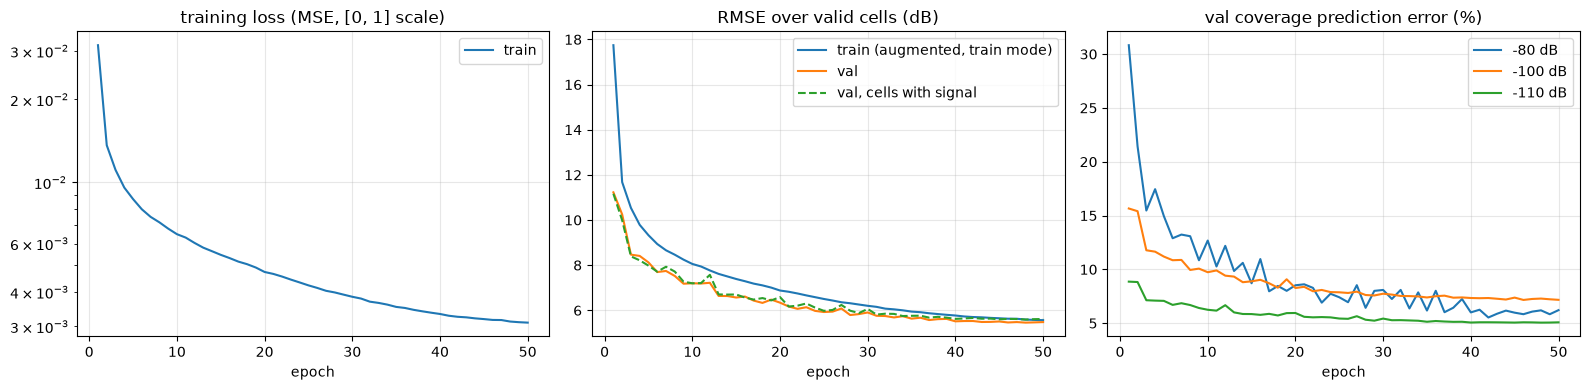

In [18]:
history = json.loads((RUN_DIR / "history.json").read_text())
ep = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogy(ep, [h["train_loss"] for h in history], label="train")
axes[0].set_title("training loss (MSE, [0, 1] scale)")
if "train_rmse_db" in history[0]:
    axes[1].plot(ep, [h["train_rmse_db"] for h in history], label="train (augmented, train mode)")
axes[1].plot(ep, [h["val_rmse_db"] for h in history], label="val")
axes[1].plot(ep, [h["val_rmse_signal_db"] for h in history], "--", label="val, cells with signal")
axes[1].set_title("RMSE over valid cells (dB)")
for t in CFG["coverage_thresholds_db"]:
    axes[2].plot(ep, [100 * h[f"val_cov_err@{t:g}"] for h in history], label=f"{t:g} dB")
axes[2].set_title("val coverage prediction error (%)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=120)
plt.show()

## 6. Testing
The best checkpoint (by `val` RMSE) is evaluated on `val`, `test` (same city families as training) and `ood`
(canyon, courtyard, hilly: unseen families). A **free space baseline** (path gain without any building) is shown
next to it, to put the numbers in context.

In [19]:
import pandas as pd

ck = torch.load(RUN_DIR / "best.pt", map_location=DEVICE, weights_only=False)
best_model = RMTransformer(**ck["model_kwargs"]).to(DEVICE)
best_model.load_state_dict(ck["model"])
best_model.eval()
print(f"best checkpoint: epoch {ck['epoch']}, val RMSE {ck['val']['rmse_db']:.3f} dB")

predictors = {"RMTransformer": model_predictor(best_model), "free space": free_space_predictor()}
eval_sets = {"val": val_set, "test": test_set, "ood": ood_set}
results = {(m, s): evaluate(p, d) for m, p in predictors.items() for s, d in eval_sets.items()}

summary = pd.DataFrame({k: summarize(r) for k, r in results.items()}).T
summary.index.names = ["model", "split"]
pd.set_option("display.precision", 4)
summary

best checkpoint: epoch 48, val RMSE 5.456 dB


maps  rmse_db  rmse_db_pooled   mae_db  bias_db  \
model         split                                                      
RMTransformer val    1620.0   5.4557          6.0276   3.5240  -0.1300   
              test   1620.0   5.6258          6.1921   3.6394  -0.0537   
              ood    3240.0   6.2560          7.1547   3.8532   0.6722   
free space    val    1620.0  17.7194         19.9591  12.5064  11.6472   
              test   1620.0  18.6526         20.9064  13.3348  12.5047   
              ood    3240.0  21.0717         23.6787  14.7562  13.8538   

                     rmse_signal_db   nrmse  cov_err@-80  boundary_rmse@-80  \
model         split                                                           
RMTransformer val            5.5914  0.0603       0.0620             5.8428   
              test           5.7554  0.0619       0.0589             5.7149   
              ood            5.7367  0.0715       0.0480             5.0493   
free space    val           17.8308  0.1996       0.3796             7.4380   
              test          18.6338  0.2091       0.3789             7.4320   
              ood           19.6059  0.2368       0.3627             7.2785   

                     cov_err@-100  boundary_rmse@-100  cov_err@-110  \
model         split                                                   
RMTransformer val          0.0729              7.6670        0.0505   
              test         0.0762              7.8118        0.0552   
              ood          0.0657              7.5326        0.0651   
free space    val          0.2377             24.4061        0.1155   
              test         0.2611             24.6561        0.1305   
              ood          0.2965             24.5467        0.1692   

                     boundary_rmse@-110  
model         split                      
RMTransformer val                9.8188  
              test               9.8745  
              ood                9.9935  
free space    val               34.3435  
              test              34.5169  
              ood               35.6689

In [20]:
# per family and per altitude (RMTransformer)
rows = []
for s, d in eval_sets.items():
    r = results[("RMTransformer", s)]
    for fam in np.unique(r["family"]):
        rows.append(dict(split=s, group="family", value=fam, **summarize(r, mask=r["family"] == fam)))
    for alt in np.unique(r["altitude"]):
        rows.append(dict(split=s, group="altitude", value=f"{alt:g} m", **summarize(r, mask=r["altitude"] == alt)))
breakdown = pd.DataFrame(rows).set_index(["split", "group", "value"])
cols = ["maps", "rmse_db", "mae_db", "bias_db", "rmse_signal_db"] + \
       [c for t in CFG["coverage_thresholds_db"] for c in (f"cov_err@{t:g}", f"boundary_rmse@{t:g}")]
breakdown[cols]

maps  rmse_db  mae_db  bias_db  rmse_signal_db  \
split group    value                                                         
val   family   blocks      540.0   5.2402  3.3510  -0.0225          5.4103   
               downtown    540.0   6.6411  4.3667  -0.1318          6.5579   
               grid        540.0   4.4858  2.8470  -0.2383          4.6443   
      altitude 15 m        405.0   7.6198  5.1738  -0.0530          7.3554   
               30 m        405.0   5.8964  3.8827  -0.1736          5.9382   
               45 m        405.0   4.6002  2.9539  -0.1798          4.8486   
               60 m        405.0   3.7064  2.3467  -0.1038          4.0859   
test  family   blocks      540.0   5.2321  3.3323  -0.1570          5.4489   
               downtown    540.0   7.0244  4.6537   0.0346          6.9175   
               grid        540.0   4.6210  2.9294  -0.0368          4.6935   
      altitude 15 m        405.0   7.7503  5.2527   0.0656          7.5031   
               30 m        405.0   6.1372  4.0267  -0.1269          6.1494   
               45 m        405.0   4.7537  3.0748  -0.1063          5.0218   
               60 m        405.0   3.8621  2.4697  -0.0317          4.2519   
ood   family   canyon     1080.0   7.3264  4.6190   1.5809          6.4675   
               courtyard  1080.0   5.9482  3.4460   0.6320          5.0073   
               hilly      1080.0   5.4933  3.5333  -0.1492          5.7036   
      altitude 15 m        810.0   9.4921  5.9997   1.4794          7.6633   
               30 m        810.0   6.9466  4.3485   0.8153          6.2306   
               45 m        810.0   4.8653  3.0719   0.3522          4.9587   
               60 m        810.0   3.7198  2.3601   0.1776          4.0270   

                          cov_err@-80  boundary_rmse@-80  cov_err@-100  \
split group    value                                                     
val   family   blocks          0.0648             5.7458        0.0708   
               downtown        0.0656             6.6164        0.0833   
               grid            0.0553             4.8679        0.0644   
      altitude 15 m            0.0508             6.8139        0.0962   
               30 m            0.0592             6.0357        0.0807   
               45 m            0.0652             5.4467        0.0647   
               60 m            0.0709             4.7976        0.0538   
test  family   blocks          0.0655             5.7236        0.0750   
               downtown        0.0559             6.4399        0.0906   
               grid            0.0551             4.8131        0.0627   
      altitude 15 m            0.0465             6.6728        0.0941   
               30 m            0.0555             5.9178        0.0835   
               45 m            0.0629             5.3677        0.0703   
               60 m            0.0686             4.7057        0.0598   
ood   family   canyon          0.0360             4.5524        0.0716   
               courtyard       0.0423             4.1295        0.0431   
               hilly           0.0650             5.8212        0.0826   
      altitude 15 m            0.0345             6.2140        0.0781   
               30 m            0.0435             5.3417        0.0700   
               45 m            0.0510             4.5983        0.0615   
               60 m            0.0604             4.0445        0.0554   

                          boundary_rmse@-100  cov_err@-110  boundary_rmse@-110  
split group    value                                                            
val   family   blocks                 7.7441        0.0432             10.5804  
               downtown               8.3517        0.0650             10.3678  
               grid                   6.6921        0.0434              8.2834  
      altitude 15 m                   8.6344        0.0850             10.8699  
               30 m                   7.5549

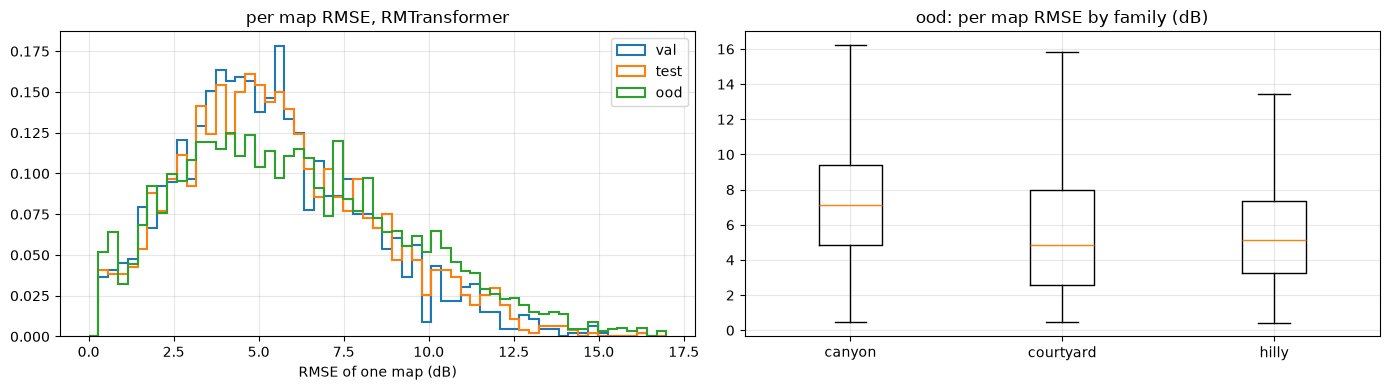

In [21]:
# distribution of the per map RMSE
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bins = np.linspace(0, max(np.percentile(results[("RMTransformer", s)]["rmse_db"], 99) for s in eval_sets), 60)
for s in eval_sets:
    axes[0].hist(results[("RMTransformer", s)]["rmse_db"], bins, histtype="step", density=True, lw=1.5, label=s)
axes[0].set_xlabel("RMSE of one map (dB)")
axes[0].set_title("per map RMSE, RMTransformer")
axes[0].legend()
r = results[("RMTransformer", "ood")]
fams = np.unique(r["family"])
axes[1].boxplot([r["rmse_db"][r["family"] == f] for f in fams], showfliers=False)
axes[1].set_xticks(range(1, len(fams) + 1), fams)
axes[1].set_title("ood: per map RMSE by family (dB)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

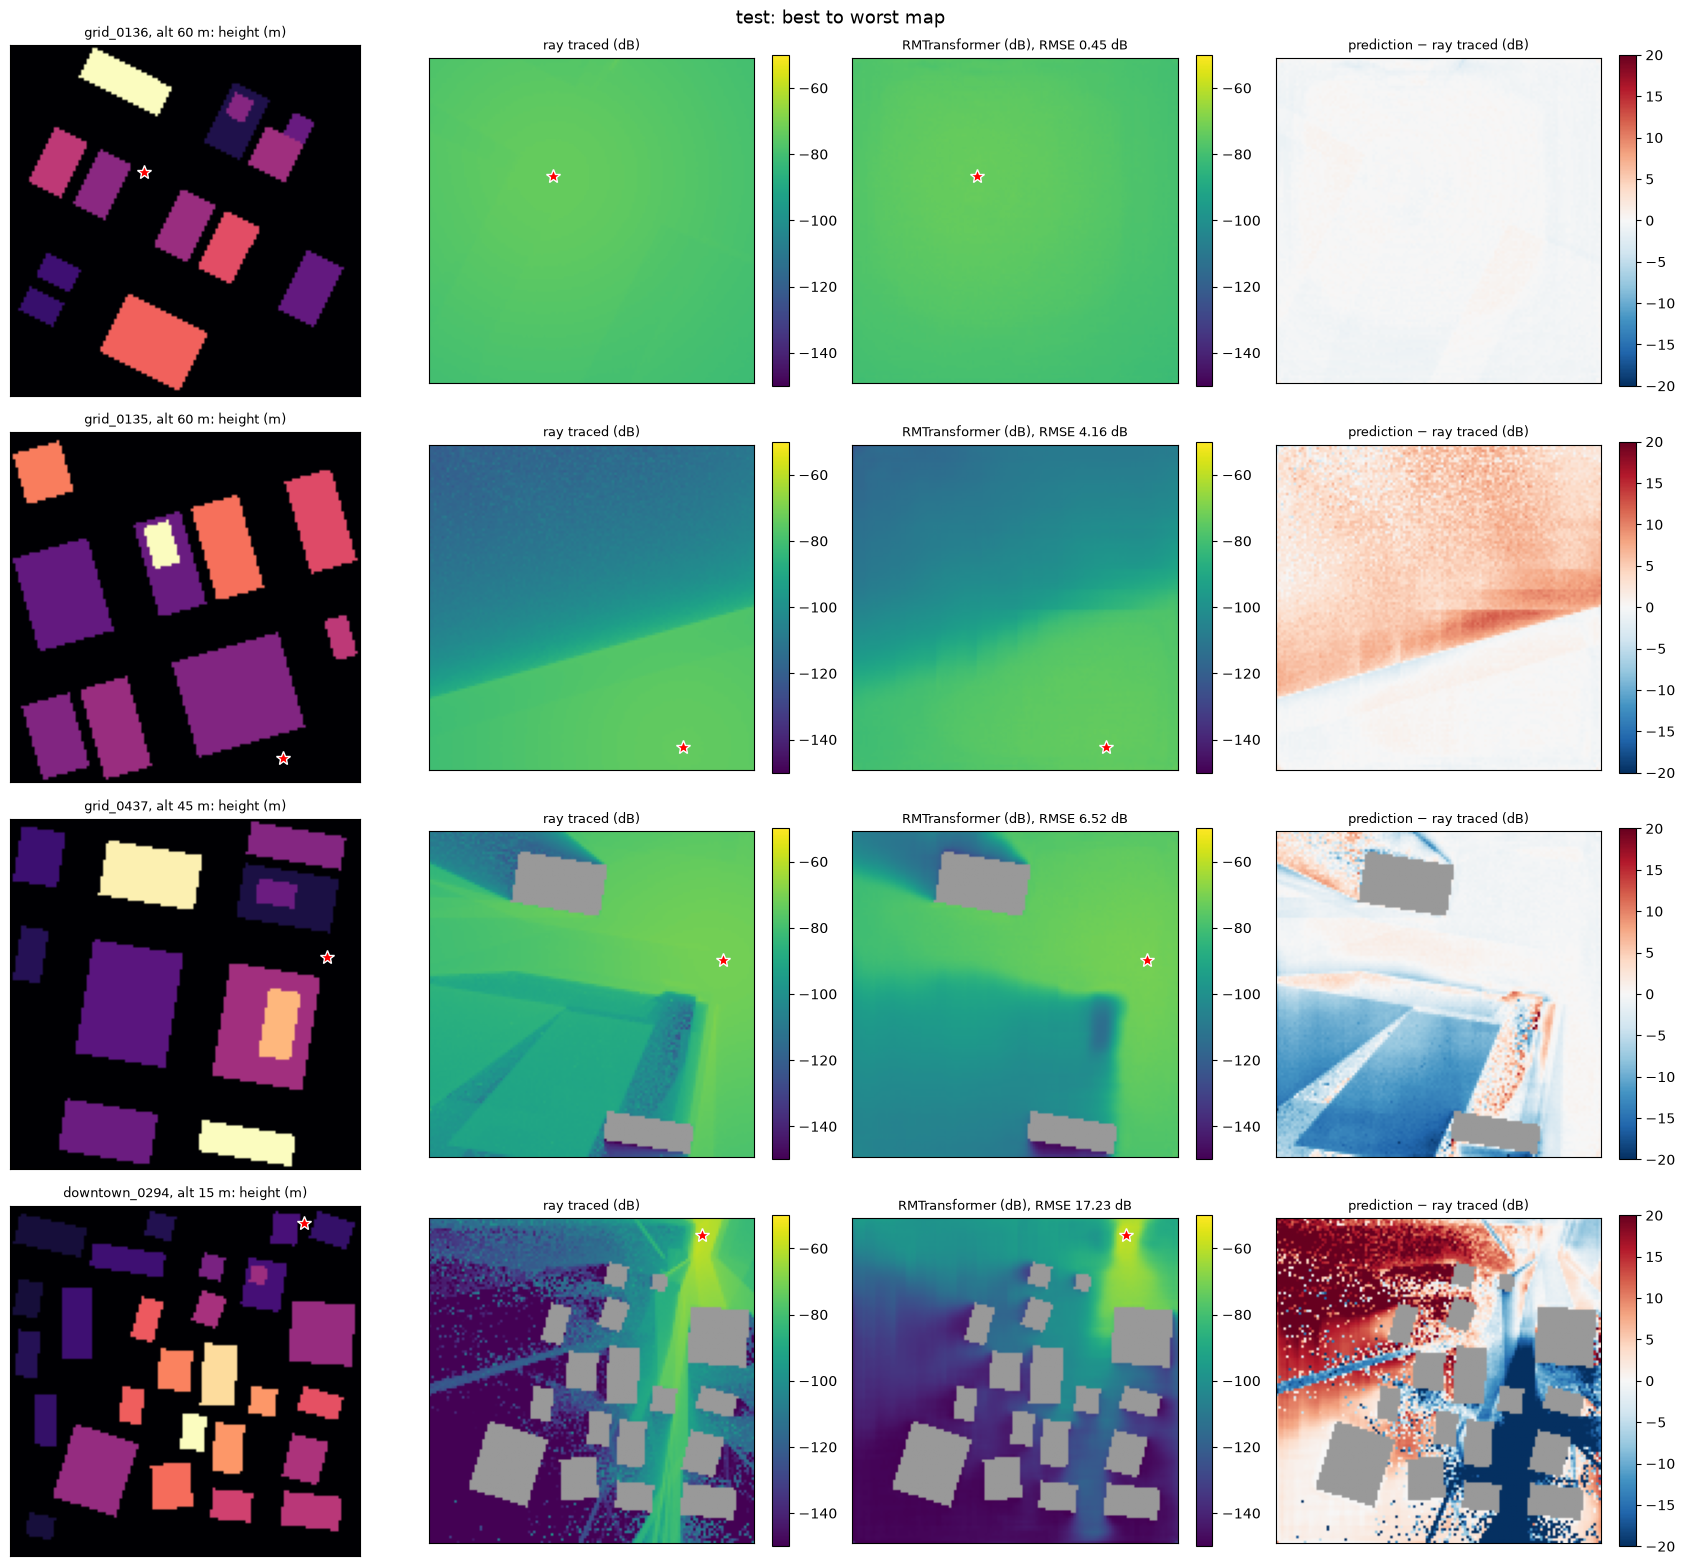

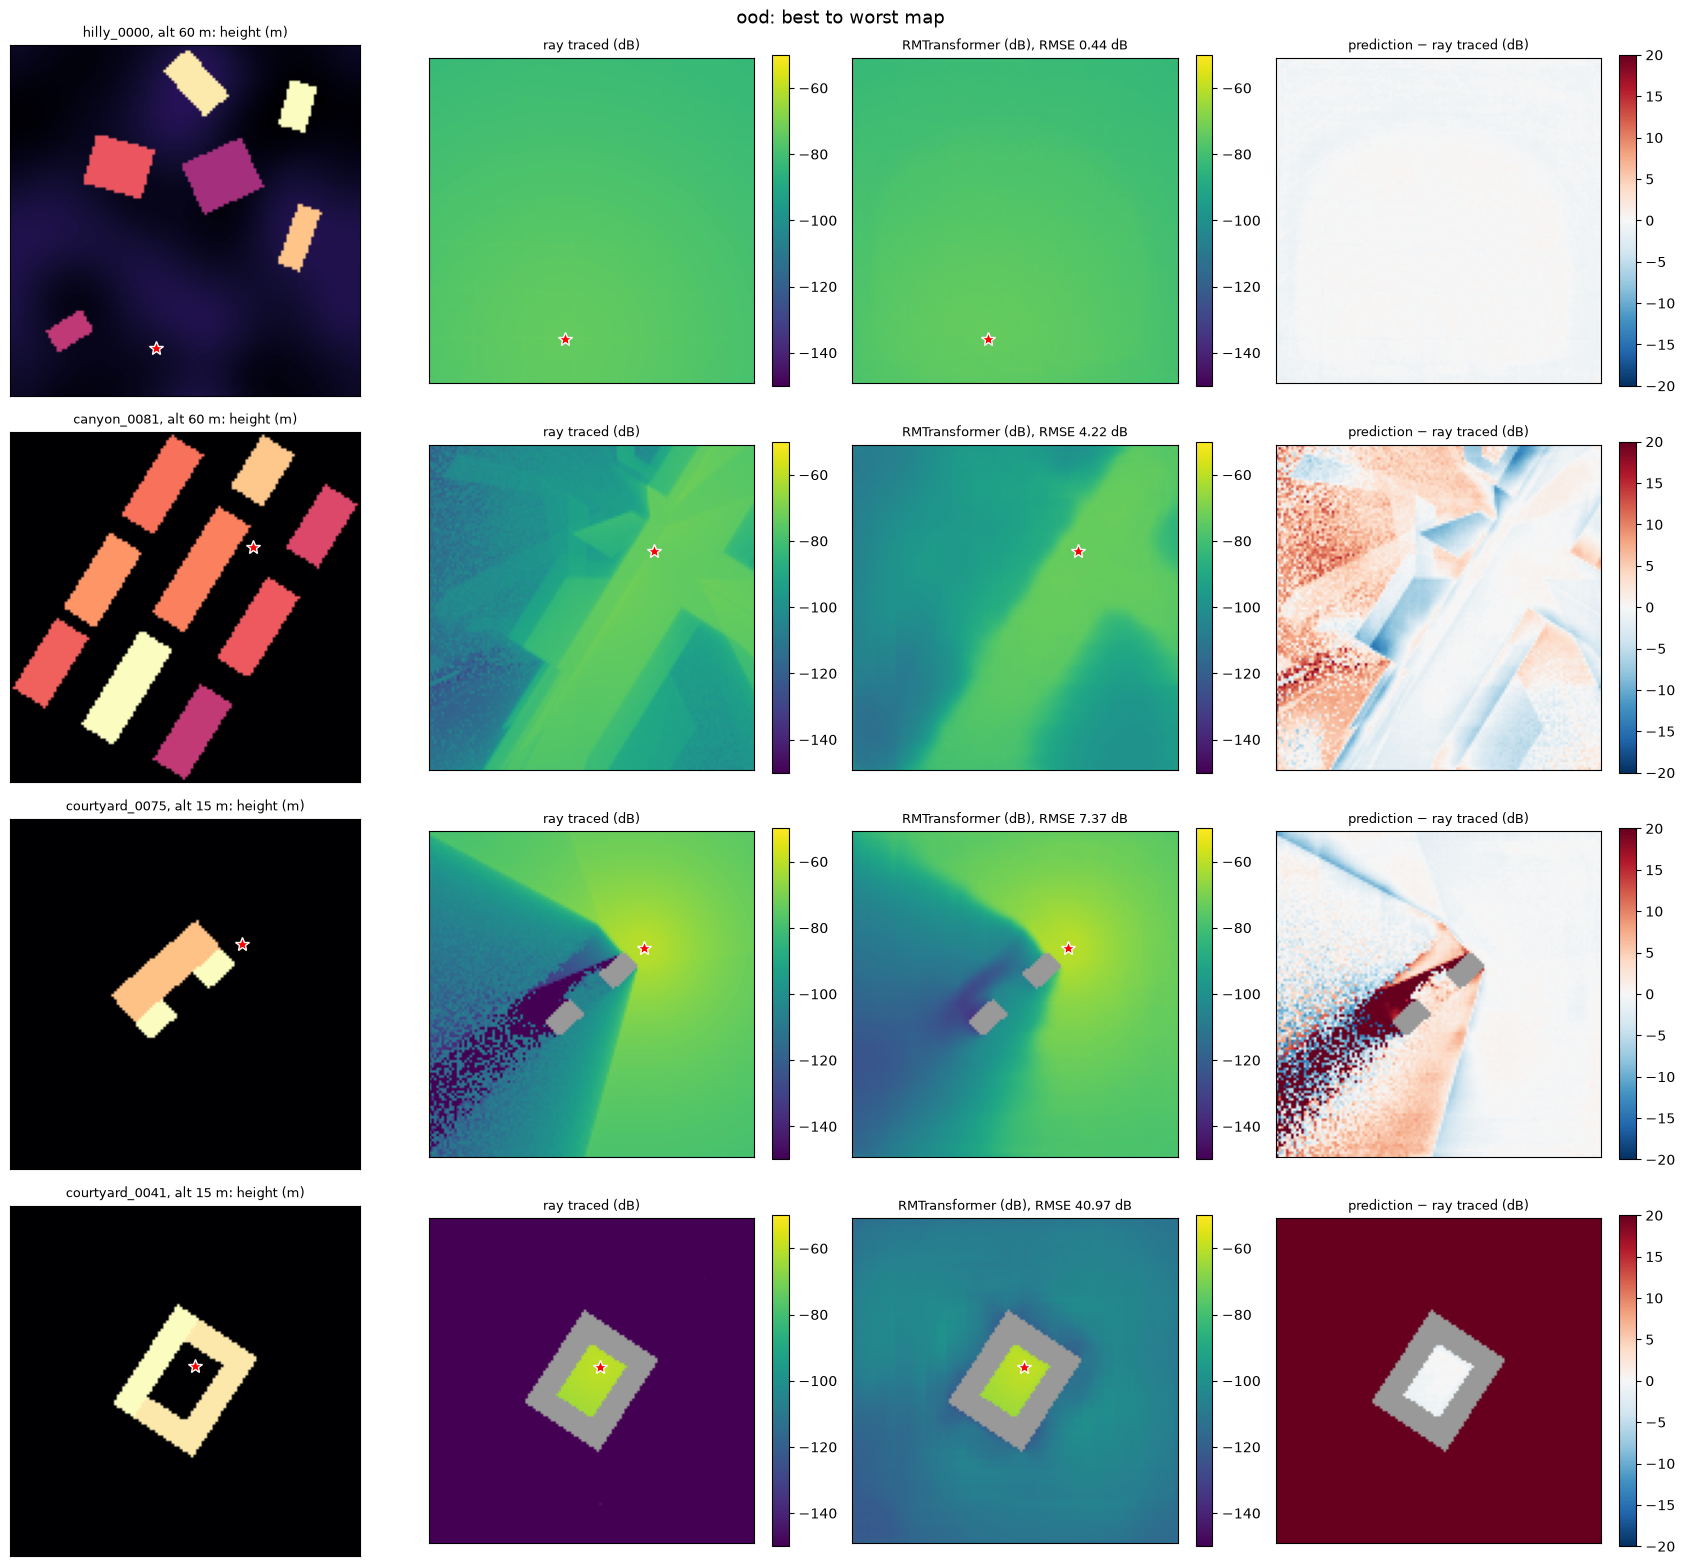

In [22]:
@torch.no_grad()
def predict_maps(predict, split, idx):
    h, st, alt, tgt = split.batch(idx, DEVICE)
    pred = predict(h, st, alt)
    valid = h < alt.view(-1, 1, 1) - 0.5
    return [t.cpu().numpy() for t in (h, st, alt, tgt.clamp_min(CFG["floor_db"]), pred, valid)]


def plot_examples(split, res, n=4, title=""):
    """Best, median and worst maps of a split (by RMSE): height, ray traced, predicted, error."""
    order = np.argsort(res["rmse_db"])
    picks = order[np.linspace(0, len(order) - 1, n).astype(int)]
    h, st, alt, tgt, pred, valid = predict_maps(predictors["RMTransformer"], split, res["idx"][picks])
    fig, axes = plt.subplots(n, 4, figsize=(17, 4 * n))
    for row, k in enumerate(picks):
        name = split.scene_names[int(split.scene_idx[int(res["idx"][k])])]
        show_map(axes[row, 0], h[row], title=f"{name}, alt {alt[row]:.0f} m: height (m)", cmap="magma",
                 station=st[row])
        im = show_map(axes[row, 1], tgt[row], valid[row], "ray traced (dB)", CFG["floor_db"], CFG["max_db"],
                      station=st[row])
        plt.colorbar(im, ax=axes[row, 1], fraction=0.046)
        im = show_map(axes[row, 2], pred[row], valid[row], f"RMTransformer (dB), RMSE {res['rmse_db'][k]:.2f} dB",
                      CFG["floor_db"], CFG["max_db"], station=st[row])
        plt.colorbar(im, ax=axes[row, 2], fraction=0.046)
        im = show_map(axes[row, 3], pred[row] - tgt[row], valid[row], "prediction − ray traced (dB)", -20, 20,
                      cmap="RdBu_r")
        plt.colorbar(im, ax=axes[row, 3], fraction=0.046)
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


plot_examples(test_set, results[("RMTransformer", "test")], title="test: best to worst map")
plot_examples(ood_set, results[("RMTransformer", "ood")], title="ood: best to worst map")

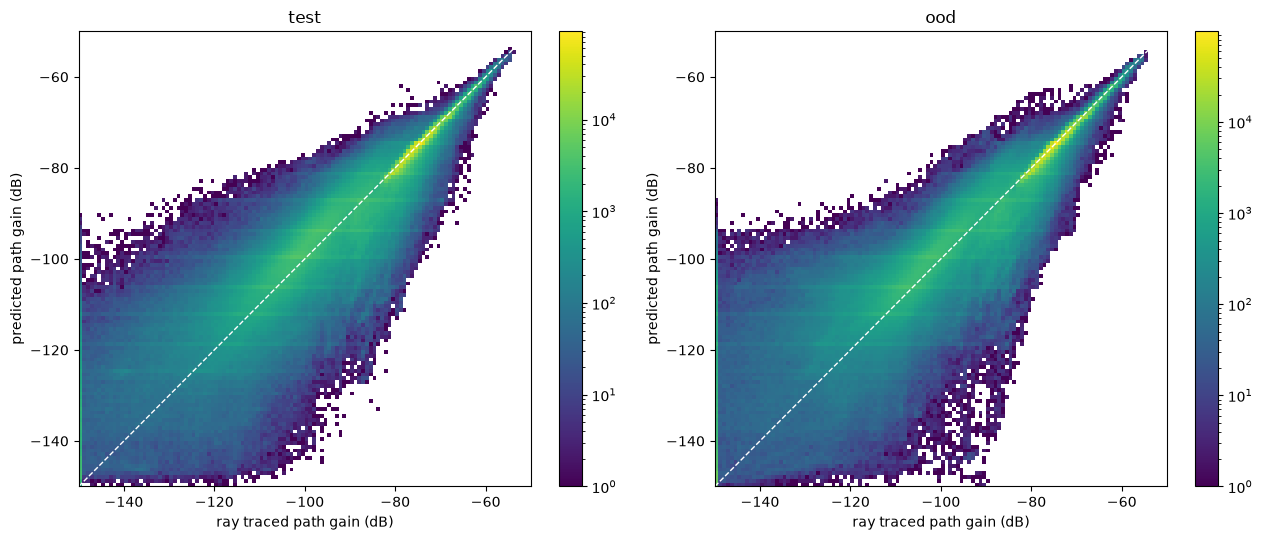

In [23]:
# predicted against ray traced path gain over the valid cells of 200 test and 200 ood maps
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (s, d) in zip(axes, [("test", test_set), ("ood", ood_set)]):
    k = np.linspace(0, len(d) - 1, min(200, len(d))).astype(int)
    _, _, _, tgt, pred, valid = predict_maps(predictors["RMTransformer"], d, k)
    hb = ax.hist2d(tgt[valid], pred[valid], bins=120, range=[[CFG["floor_db"], CFG["max_db"]]] * 2,
                   norm=LogNorm(), cmap="viridis")
    ax.plot([CFG["floor_db"], CFG["max_db"]], [CFG["floor_db"], CFG["max_db"]], "w--", lw=1)
    ax.set_xlabel("ray traced path gain (dB)")
    ax.set_ylabel("predicted path gain (dB)")
    ax.set_title(s)
    plt.colorbar(hb[3], ax=ax)
plt.tight_layout()
plt.show()

### Speed against ray tracing
This is the time to predict one map, from height map, station and altitude already on the GPU to the dB map. It
includes building the input channels and synchronises the GPU. It is compared with the dataset's `rt_time` (one
Sionna `RadioMapSolver` call per map). `rt_time` was measured on the dataset authors' GPUs, so the speedup is only
exact when this notebook runs on the same hardware.

In [24]:
def benchmark(predict, split, batch_sizes=(1, 8, 32), n_iter=50, warmup=10):
    rows = []
    for bs in batch_sizes:
        h, st, alt, _ = split.batch(np.arange(bs), DEVICE)
        for _ in range(warmup):
            predict(h, st, alt)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n_iter):
            predict(h, st, alt)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        per_map = (time.perf_counter() - t0) / (n_iter * bs)
        rows.append(dict(batch=bs, ms_per_map=1e3 * per_map))
    return pd.DataFrame(rows)


speed = benchmark(predictors["RMTransformer"], test_set)
rt = float(np.median(test_set.rt_time))
speed["speedup_vs_ray_tracing"] = rt / (speed["ms_per_map"] / 1e3)
print(f"ray tracing (test split, median rt_time): {1e3 * rt:.0f} ms per map")
print("median rt_time per source:", {s: round(float(np.median(test_set.rt_time[test_set.source == s])), 3)
                                     for s in np.unique(test_set.source)})
speed

ray tracing (test split, median rt_time): 309 ms per map
median rt_time per source: {np.str_('mahdi'): 0.298, np.str_('sami'): 0.356, np.str_('yessine'): 0.285}


,batch,ms_per_map,speedup_vs_ray_tracing
0,1,23.7457,13.0316
1,8,6.0521,51.1298
2,32,6.2206,49.7451


In [25]:
# save everything needed for the report
per_map = pd.concat([pd.DataFrame(dict(model=m, split=s, map=r["idx"], family=r["family"], altitude=r["altitude"],
                                       source=r["source"], rmse_db=r["rmse_db"], mae_db=r["mae_db"],
                                       rt_time=r["rt_time"]))
                     for (m, s), r in results.items()], ignore_index=True)
per_map.to_csv(RUN_DIR / "per_map_metrics.csv", index=False)
summary.to_csv(RUN_DIR / "summary.csv")
breakdown.to_csv(RUN_DIR / "breakdown.csv")
speed.to_csv(RUN_DIR / "speed.csv", index=False)
(RUN_DIR / "results.json").write_text(json.dumps(dict(
    checkpoint_epoch=ck["epoch"], cfg=CFG, model_kwargs=ck["model_kwargs"],
    parameters=sum(p.numel() for p in best_model.parameters()),
    summary={f"{m}/{s}": summarize(r) for (m, s), r in results.items()},
    speed=speed.to_dict(orient="records"), median_rt_time_test=rt), indent=2,
    default=lambda o: o.item() if hasattr(o, "item") else list(o)))
print("saved to", RUN_DIR.resolve())

saved to D:\Multidisciplinary project\git-repo\Neural-Prediction-of-RF-Coverage-Maps\training\runs\rmtransformer


## Notes and things to try
* **No signal cells.** About 2 % of valid cells (4 % in `ood`) sit at -150 dB, about 70 dB below the median.
  With MSE they weigh a lot. Options are to raise `floor_db` (e.g. -130 dB; the metrics then use the same floor),
  to switch to `loss="huber"`, or to add a second "signal / no signal" output.
* **Inputs.** `fspl` gives the model the distance falloff for free, so it only has to learn the effect of the
  buildings. To measure what each channel brings, retrain with a shorter `in_channels`.
* **Capacity.** The paper does not say how many MaxViT blocks per stage it uses. `depths=(2, 2, 2, 2)` (or
  MaxViT-T's `(2, 2, 5, 2)`) in `MODEL_PRESETS` is the obvious next step if the model underfits.
* **Generalisation.** Compare `test` and `ood` per family. `hilly` is the only family with uneven ground, and
  `canyon` / `courtyard` have street widths and building shapes never seen in training.